# Blackhat morphing

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

In [2]:
car_img = cv2.imread("car.jpg", cv2.IMREAD_GRAYSCALE)

In [3]:
# convert image to binary using Otsu’s thresholding
car_binary = cv2.threshold(car_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

In [4]:
# define the kernel 
kernel = np.ones((5, 5), np.uint8)

In [5]:
# invert the image 
inverted_car_img = cv2.bitwise_not(car_binary)

In [6]:
# use morph gradient 
blackhat_img = cv2.morphologyEx(inverted_car_img, cv2.MORPH_BLACKHAT, kernel)

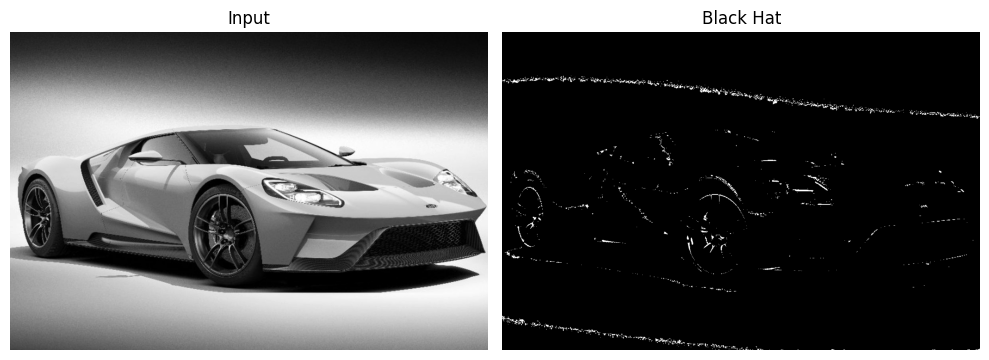

In [7]:
# Show the original grayscale image
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title("Input")
plt.imshow(car_img, cmap='gray')
plt.axis('off')

# Show the Black Hat result
plt.subplot(1, 2, 2)
plt.title("Black Hat")
plt.imshow(blackhat_img, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

# Tophat 

In [8]:
# define the kernel 
kernel = np.ones((5, 5), np.uint8)

In [9]:
# use morph gradient 
tophat_img = cv2.morphologyEx(car_binary, cv2.MORPH_TOPHAT, kernel)

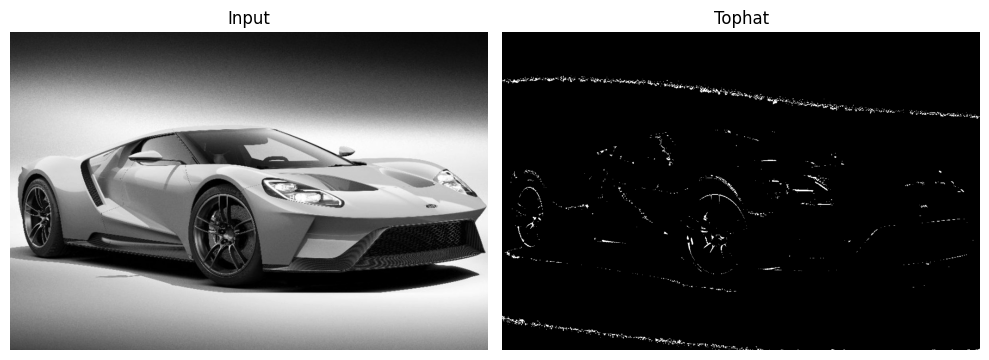

In [10]:
# Show the original grayscale image
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title("Input")
plt.imshow(car_img, cmap='gray')
plt.axis('off')

# Show the Tophat result
plt.subplot(1, 2, 2)
plt.title("Tophat")
plt.imshow(tophat_img, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

# Dilation

In [11]:
alphabet_img = cv2.imread("alphabet.jpg", cv2.IMREAD_GRAYSCALE)

In [12]:
# convert image to binary using Otsu’s thresholding
_, binary = cv2.threshold(alphabet_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

In [13]:
# define the kernel 
kernel = np.ones((12, 12), np.uint8)

# invert the image 
inverted = cv2.bitwise_not(binary)

In [14]:
# Apply dilation 
img_dilation = cv2.dilate(inverted, kernel, iterations=1)

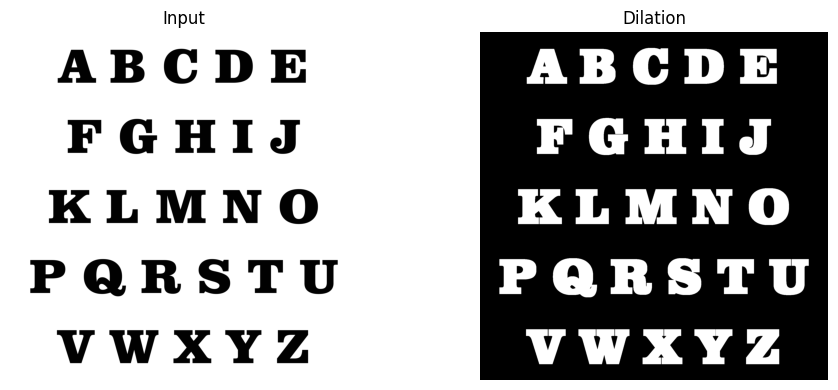

In [15]:
# Show the original grayscale image
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title("Input")
plt.imshow(alphabet_img, cmap='gray')
plt.axis('off')

# Show the dilation inout and output
plt.subplot(1, 2, 2)
plt.title("Dilation")
plt.imshow(img_dilation, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

# Erosion

In [16]:
# convert image to binary using Otsu’s thresholding
_, binary = cv2.threshold(alphabet_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# define the kernel 
kernel = np.ones((20, 20), np.uint8)

# invert the image 
inverted = cv2.bitwise_not(binary)

In [17]:
# Apply erosion 
eroded_img = cv2.erode(inverted, kernel, iterations=1)

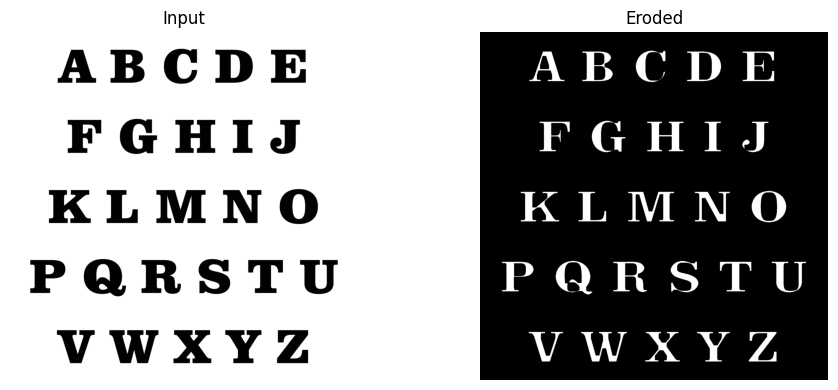

In [18]:
# Show the original grayscale image
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title("Input")
plt.imshow(alphabet_img, cmap='gray')
plt.axis('off')

# Show the erosion result
plt.subplot(1, 2, 2)
plt.title("Eroded")
plt.imshow(eroded_img, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

# Opening

In [19]:
# define the kernel 
kernel = np.ones((3, 3), np.uint8)

In [20]:
# Apply opening 
opening_img = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

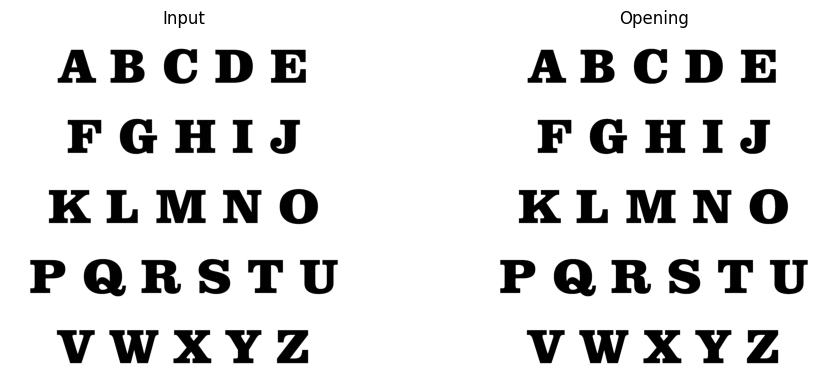

In [21]:
# Show the original grayscale image
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title("Input")
plt.imshow(alphabet_img, cmap='gray')
plt.axis('off')

# Show the opening result
plt.subplot(1, 2, 2)
plt.title("Opening")
plt.imshow(opening_img, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

In [22]:
ssim_value, _ = ssim(alphabet_img, opening_img, full=True)
print(f"Structural Similarity Index (SSIM): {ssim_value:.4f}")


Structural Similarity Index (SSIM): 0.8548


# Closing 

In [23]:
# convert image to binary using Otsu’s thresholding
_, binary = cv2.threshold(alphabet_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

In [24]:
# define the kernel 
kernel = np.ones((20, 20), np.uint8)

In [25]:
# Apply closing
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=1)

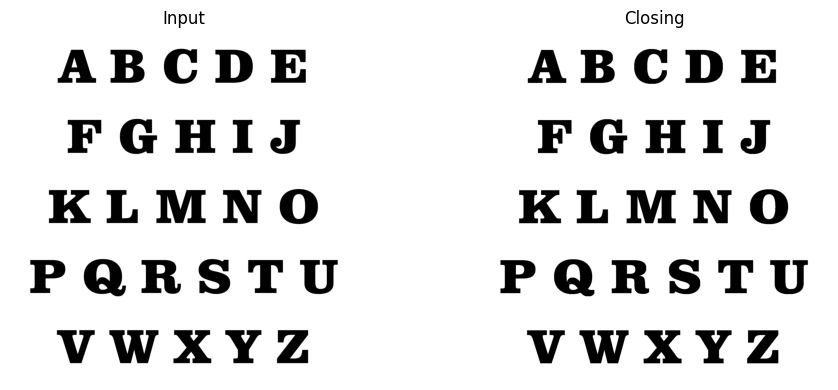

In [26]:
# Show the original grayscale image
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title("Input")
plt.imshow(alphabet_img, cmap='gray')
plt.axis('off')

# Shows the closing output
plt.subplot(1, 2, 2)
plt.title("Closing")
plt.imshow(closing, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

In [27]:
ssim_value, _ = ssim(alphabet_img, closing, full=True)
print(f"Structural Similarity Index (SSIM): {ssim_value:.4f}")


Structural Similarity Index (SSIM): 0.8362
